# 4. Análisis univariado (2.2)

Se analiza cada variable en dos niveles, siempre con el periodo de **entrenamiento**:

- **Catálogo** (una fila por sismo): magnitud, profundidad, coordenadas, departamento, escala de
  magnitud y calidad de la localización.
- **Panel** (celda × mes): las 18 predictoras del modelo base.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Datos de entrenamiento: panel y catálogo limpio hasta el fin del entrenamiento
ev_, X, info, tr, gp, te = datos.panel_completo()
P = datos.panel_dataframe(X, info, tr)
fin_tr = datos.fecha_de_mes(info["m_test"] - cfg.GAP_MESES)[0]
crudo = datos.leer_crudos()
cat_tr, _ = datos.limpiar(crudo)
cat_tr = cat_tr[cat_tr.time < fin_tr]
md(f"Sismos del catálogo en el periodo de entrenamiento (antes de {fin_tr:%Y-%m-%d}): **{es(len(cat_tr), 0)}**; filas del panel de entrenamiento: **{es(len(P), 0)}**.")

Sismos del catálogo en el periodo de entrenamiento (antes de 2020-12-01): **29.365**; filas del panel de entrenamiento: **30.970**.

## 4.1 Variables numéricas del catálogo

In [3]:
# Resumen numérico (media, cuantiles, asimetría, curtosis, atípicos) de las variables del catálogo
num_cat = ["mag", "depth", "latitude", "longitude", "fases", "rms", "gap_az", "err_lat", "err_lon", "err_prof"]
r_cat = eda.resumen_numerico(cat_tr[num_cat])
eda.guardar_tabla(r_cat.reset_index().rename(columns={"index": "variable"}), "univariado_catalogo.csv")
r_cat.round(2)

,n,faltantes,media,mediana,desv_est,mín,p01,p25,p75,p99,máx,asimetría,curtosis,ceros_%,únicos,atípicos_IQR_%
mag,29365,0,2.93,2.80,0.46,2.50,2.50,2.60,3.10,4.50,6.70,1.80,4.45,0.00,41,5.42
depth,29365,0,98.50,140.70,62.42,-1.99,0.00,22.80,147.60,161.64,594.80,-0.60,-1.13,5.85,3832,0.01
latitude,29365,0,6.29,6.81,1.78,-2.65,0.97,5.77,6.84,11.23,13.67,-0.55,2.11,0.00,6906,19.57
longitude,29365,0,-74.14,-73.16,1.81,-81.96,-79.48,-74.96,-73.09,-71.44,-70.15,-1.31,0.73,0.00,6251,6.80
fases,29365,0,17.70,11.00,16.80,3.00,4.00,7.00,21.00,79.00,101.00,2.02,3.87,0.00,98,9.96
rms,29363,2,0.56,0.50,0.23,0.00,0.20,0.40,0.60,1.30,9.40,5.99,147.60,0.05,35,8.65
gap_az,29363,2,150.53,145.00,67.26,21.00,45.00,96.00,195.00,310.00,360.00,0.34,-0.61,0.00,327,0.06
err_lat,29363,2,5.69,3.80,7.83,0.28,0.71,2.60,6.00,41.34,99.90,6.24,52.83,0.00,1030,8.07
err_lon,29363,2,8.37,5.20,10.07,0.28,0.71,2.90,10.30,55.30,99.90,4.08,23.80,0.00,1176,6.19
err_prof,29363,2,10.50,6.90,13.20,0.00,1.20,4.80,10.70,82.40,99.90,4.20,20.94,0.18,1095,9.33


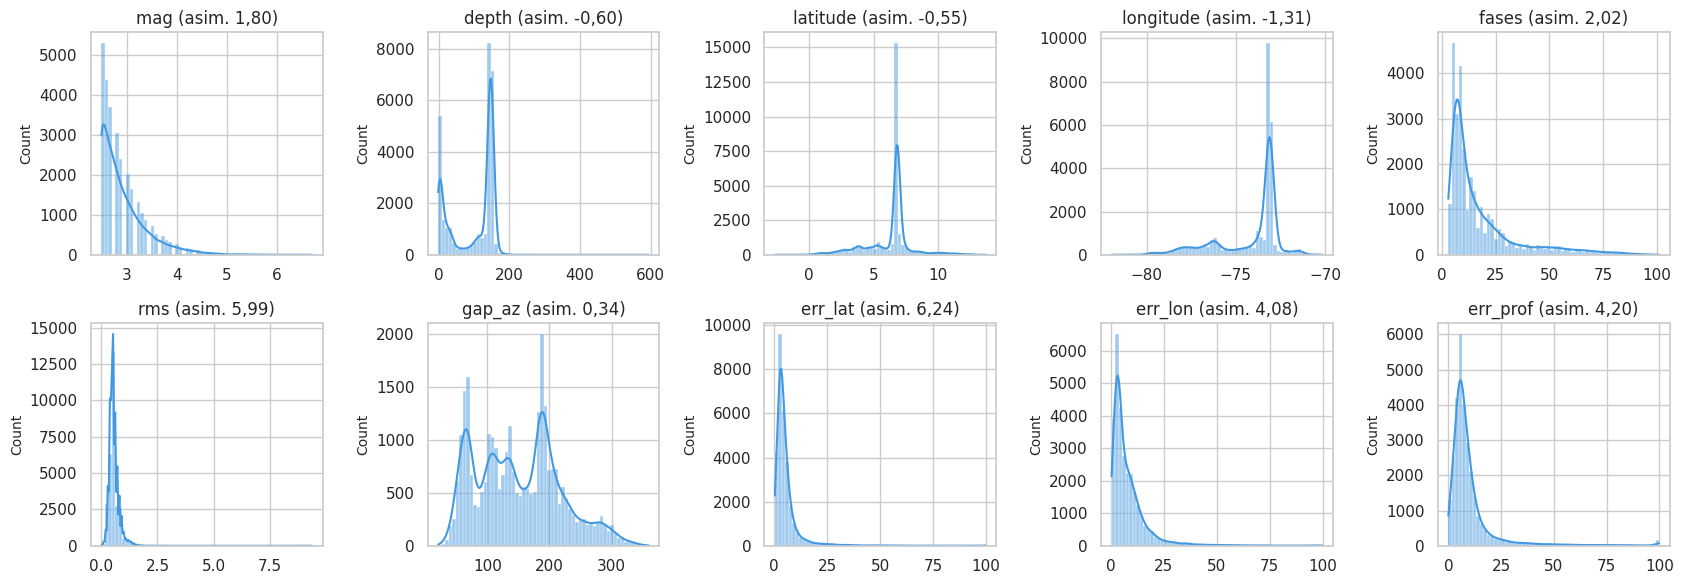

In [4]:
# Histogramas con densidad de las variables del catálogo
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, c in zip(axes.ravel(), num_cat):
    sns.histplot(cat_tr[c], bins=60, kde=True, ax=ax, color="#4299e1")
    ax.set_title(f"{c} (asim. {es(r_cat.loc[c, 'asimetría'], 2)})"); ax.set_xlabel("")
plt.tight_layout(); eda.guardar_figura(fig, "04_histogramas_catalogo.png"); plt.show()

## 4.2 Variables numéricas del panel (predictoras del modelo base)

In [5]:
# Resumen numérico de las 18 predictoras del panel
r_pan = eda.resumen_numerico(P[X.columns])
eda.guardar_tabla(r_pan.reset_index().rename(columns={"index": "variable"}), "univariado_panel.csv")
r_pan.round(2)

,n,faltantes,media,mediana,desv_est,mín,p01,p25,p75,p99,máx,asimetría,curtosis,ceros_%,únicos,atípicos_IQR_%
n_1m,30970,0,0.81,0.00,5.71,0.00,0.00,0.00,0.00,7.00,148.00,13.18,191.69,76.26,98,23.74
n_3m,30970,0,2.44,0.00,16.66,0.00,0.00,0.00,1.00,18.00,336.00,12.97,181.90,51.88,188,12.34
n_6m,30970,0,4.90,1.00,33.13,0.00,0.00,0.00,3.00,37.00,685.00,13.09,185.65,32.92,251,6.14
n_12m,30970,0,9.90,3.00,66.33,0.00,0.00,1.00,5.00,78.00,1314.00,13.17,187.85,16.08,305,8.26
n35_3m,30970,0,0.30,0.00,2.22,0.00,0.00,0.00,0.00,3.00,48.00,13.22,195.85,89.15,47,10.85
n35_12m,30970,0,1.21,0.00,8.56,0.00,0.00,0.00,1.00,9.00,176.00,13.33,195.01,67.29,124,4.83
mag_media_3m,14904,16066,2.92,2.84,0.38,2.50,2.50,2.67,3.10,4.30,5.50,1.78,4.86,0.00,1420,3.89
mag_media_12m,25990,4980,2.94,2.89,0.32,2.50,2.50,2.73,3.07,4.13,5.30,1.81,5.71,0.00,3441,4.77
mag_max_3m,14904,16066,3.13,3.00,0.58,2.50,2.50,2.70,3.40,5.20,6.70,1.53,2.93,0.00,41,3.84
mag_max_12m,25990,4980,3.38,3.30,0.65,2.50,2.50,2.90,3.70,5.50,6.70,1.11,1.63,0.00,41,2.53


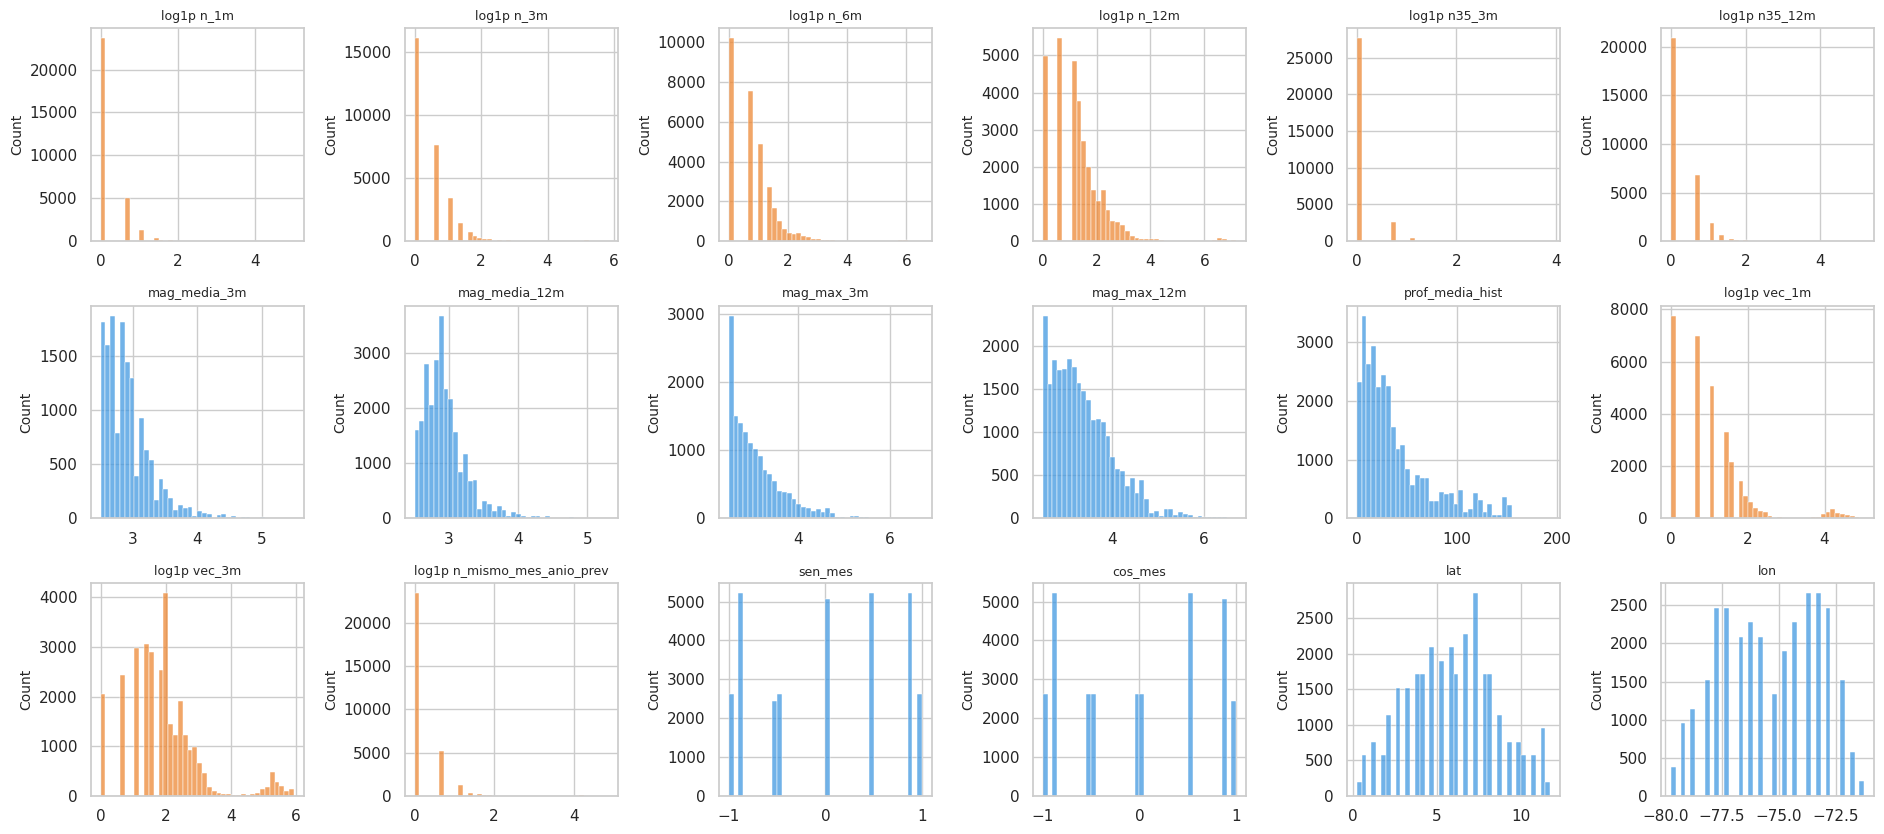

In [6]:
# Histogramas de las predictoras; los conteos se muestran en log1p por su asimetría
fig, axes = plt.subplots(3, 6, figsize=(19, 8.5))
for ax, c in zip(axes.ravel(), X.columns):
    x = P[c].dropna()
    es_conteo = c.startswith(("n_", "n35", "vec", "n_mismo"))
    sns.histplot(np.log1p(x) if es_conteo else x, bins=40, ax=ax, color="#ed8936" if es_conteo else "#4299e1")
    ax.set_title(("log1p " if es_conteo else "") + c, fontsize=9); ax.set_xlabel("")
plt.tight_layout(); eda.guardar_figura(fig, "04_histogramas_panel.png"); plt.show()

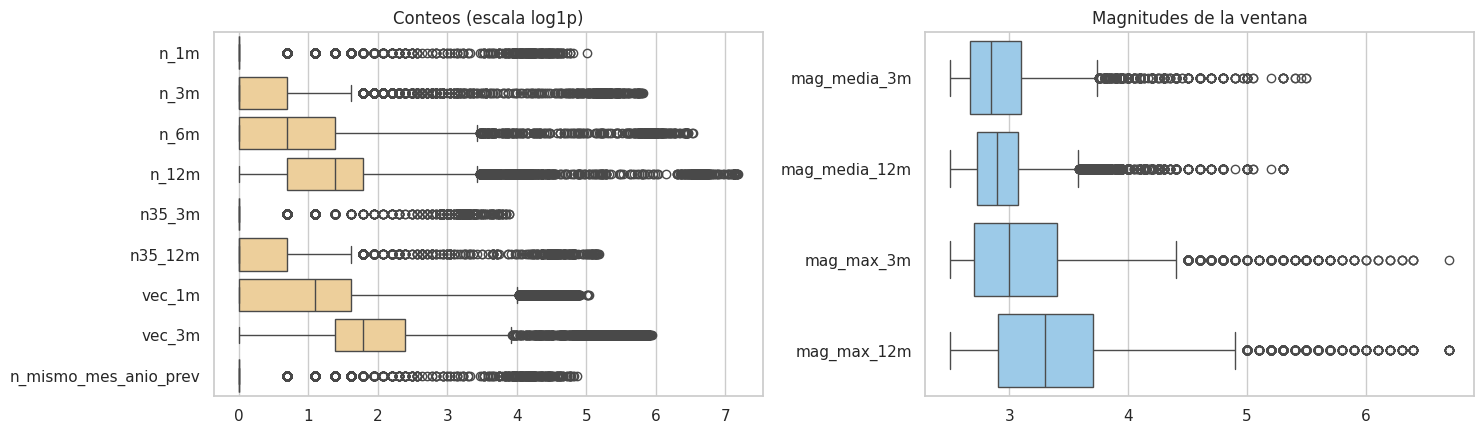

In [7]:
# Diagramas de caja de conteos (log1p) y magnitudes
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
conteos = [c for c in X.columns if c.startswith(("n_", "n35", "vec", "n_mismo"))]
sns.boxplot(data=np.log1p(P[conteos]), orient="h", ax=axes[0], color="#fbd38d"); axes[0].set_title("Conteos (escala log1p)")
otras = ["mag_media_3m", "mag_media_12m", "mag_max_3m", "mag_max_12m"]
sns.boxplot(data=P[otras], orient="h", ax=axes[1], color="#90cdf4"); axes[1].set_title("Magnitudes de la ventana")
plt.tight_layout(); eda.guardar_figura(fig, "04_boxplots_panel.png"); plt.show()

## 4.3 Pruebas de normalidad (con cautela)

Con decenas de miles de filas, cualquier desviación mínima rechaza la normalidad, así que el p-valor
por sí solo no informa. Se reportan la prueba de **D'Agostino-Pearson** (asimetría y curtosis
conjuntas) y la de **Shapiro-Wilk** sobre una submuestra de 5.000, junto con la asimetría y la
curtosis, que son las que sí guían decisiones.

In [8]:
# Pruebas de normalidad (D'Agostino y Shapiro sobre submuestra) para justificar transformaciones
filas = []
rng = np.random.default_rng(cfg.SEMILLA)
for c in ["mag", "depth"]:
    x = cat_tr[c].to_numpy()
    filas.append(("catálogo", c, *stats.normaltest(x), stats.shapiro(rng.choice(x, 5000, replace=False))[1], stats.skew(x), stats.kurtosis(x)))
for c in X.columns:
    x = P[c].dropna().to_numpy()
    if np.std(x) == 0:
        continue
    xx = np.log1p(x) if c.startswith(("n_", "n35", "vec", "n_mismo")) else x
    filas.append(("panel", c + (" (log1p)" if xx is not x else ""), *stats.normaltest(xx),
                  stats.shapiro(rng.choice(xx, min(5000, len(xx)), replace=False))[1], stats.skew(xx), stats.kurtosis(xx)))
norm = pd.DataFrame(filas, columns=["nivel", "variable", "K2_DAgostino", "p_DAgostino", "p_Shapiro_5000", "asimetría", "curtosis"])
norm["p_DAgostino_Holm"] = eda.holm(norm.p_DAgostino)
eda.guardar_tabla(norm, "normalidad.csv")
norm.round(4)

,nivel,variable,K2_DAgostino,p_DAgostino,p_Shapiro_5000,asimetría,curtosis,p_DAgostino_Holm
0,catálogo,mag,10620.6999,0.0,0.0,1.8047,4.4516,0.0
1,catálogo,depth,16631.5186,0.0,0.0,-0.5970,-1.1331,0.0
2,panel,n_1m (log1p),25869.0101,0.0,0.0,3.9413,23.2740,0.0
3,panel,n_3m (log1p),17389.0103,0.0,0.0,2.5014,11.2721,0.0
4,panel,n_6m (log1p),12718.9507,0.0,0.0,1.8388,7.2725,0.0
5,panel,n_12m (log1p),9419.7604,0.0,0.0,1.3897,5.3644,0.0
6,panel,n35_3m (log1p),33497.7806,0.0,0.0,5.6174,41.5601,0.0
7,panel,n35_12m (log1p),23158.5485,0.0,0.0,3.4235,19.0523,0.0
8,panel,mag_media_3m,5430.7290,0.0,0.0,1.7761,4.8551,0.0
9,panel,mag_media_12m,9986.5752,0.0,0.0,1.8126,5.7088,0.0


In [9]:
md(f"""**Interpretación (numéricas).**
- **Ninguna variable es normal.** La prueba rechaza en {int((norm.p_DAgostino_Holm < 0.05).sum())} de {len(norm)} variables tras Holm. Lo útil es la forma:
  - **Conteos (`n_*`, `vec_*`).** Muy asimétricos a la derecha incluso en log1p, con la mayor parte de la masa en 0 y una cola
    hacia el nido de Bucaramanga. Mediana de `n_1m` = {es(r_pan.loc['n_1m', 'mediana'], 0)}, p99 = {es(r_pan.loc['n_1m', 'p99'], 0)}, máximo = {es(r_pan.loc['n_1m', 'máx'], 0)}.
    Los atípicos por IQR ({es(r_pan.loc['n_1m', 'atípicos_IQR_%'], 0)} % en `n_1m`) son celdas muy activas reales.
    **Decisión (cap. 10):** transformar con log1p en los modelos sensibles a la escala, como SVR lineal y KNN, en lugar de recortar.
  - **Magnitudes de ventana.** Acotadas por abajo en 2,5 y asimétricas por la ley de Gutenberg-Richter. La magnitud media de
    3 meses falta en {es(r_pan.loc['mag_media_3m', 'faltantes'] / len(P), 0, pct=True)} de las filas (celdas sin sismos; capítulo 2).
  - **Profundidad media histórica.** Bimodal: celdas superficiales y celdas del nido (≈ 150 km).
  - **`sen_mes`, `cos_mes`, `lat`, `lon`.** Uniformes o discretas por construcción; la prueba de normalidad no tiene sentido
    para ellas y se reporta solo por completitud.
- **Implicación.** Los modelos lineales (SVR lineal, Ridge, Lasso) no requieren normalidad de las predictoras, pero sí se
  benefician de escalas comparables y de reducir la influencia de los extremos: de ahí log1p y estandarización.""")

**Interpretación (numéricas).**
- **Ninguna variable es normal.** La prueba rechaza en 20 de 20 variables tras Holm. Lo útil es la forma:
  - **Conteos (`n_*`, `vec_*`).** Muy asimétricos a la derecha incluso en log1p, con la mayor parte de la masa en 0 y una cola
    hacia el nido de Bucaramanga. Mediana de `n_1m` = 0, p99 = 7, máximo = 148.
    Los atípicos por IQR (24 % en `n_1m`) son celdas muy activas reales.
    **Decisión (cap. 10):** transformar con log1p en los modelos sensibles a la escala, como SVR lineal y KNN, en lugar de recortar.
  - **Magnitudes de ventana.** Acotadas por abajo en 2,5 y asimétricas por la ley de Gutenberg-Richter. La magnitud media de
    3 meses falta en 52 % de las filas (celdas sin sismos; capítulo 2).
  - **Profundidad media histórica.** Bimodal: celdas superficiales y celdas del nido (≈ 150 km).
  - **`sen_mes`, `cos_mes`, `lat`, `lon`.** Uniformes o discretas por construcción; la prueba de normalidad no tiene sentido
    para ellas y se reporta solo por completitud.
- **Implicación.** Los modelos lineales (SVR lineal, Ridge, Lasso) no requieren normalidad de las predictoras, pero sí se
  benefician de escalas comparables y de reducir la influencia de los extremos: de ahí log1p y estandarización.

## 4.4 Variables categóricas: cardinalidad, frecuencias y categorías raras

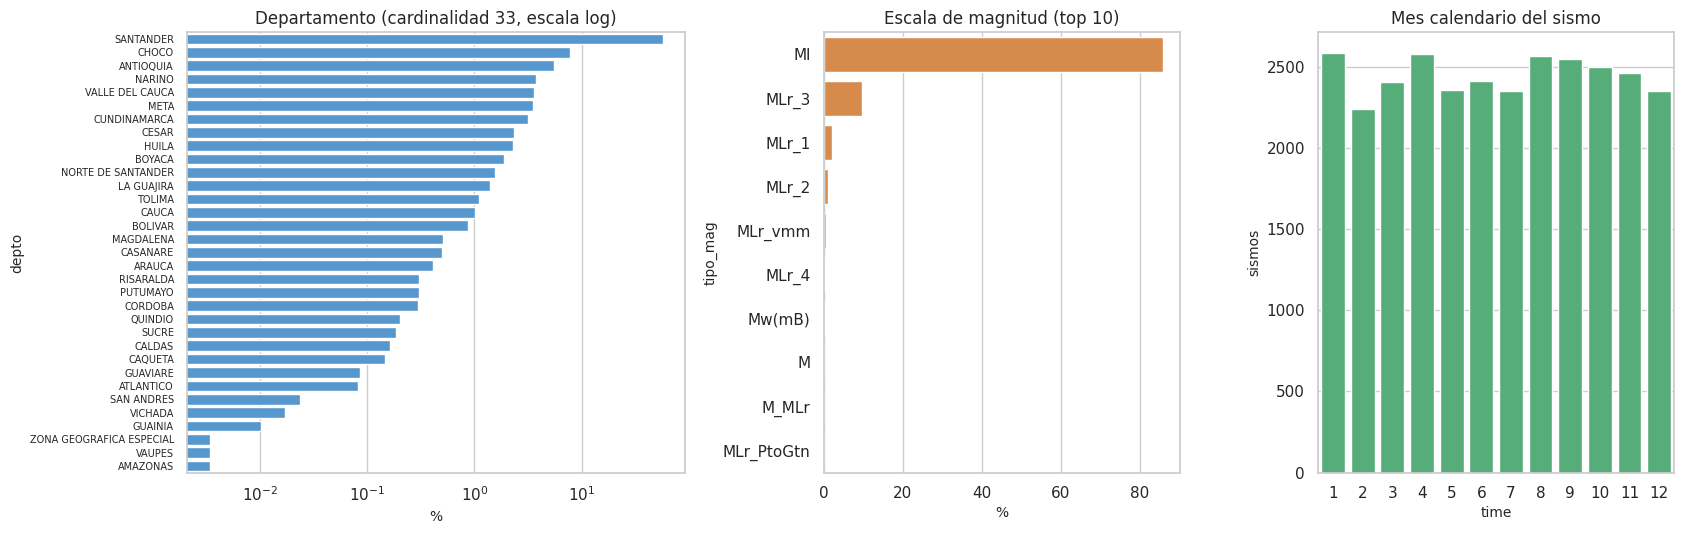

,sismos,%,rara (< 1 %)
depto,,,
SANTANDER,16714,56.92,False
CHOCO,2289,7.79,False
ANTIOQUIA,1629,5.55,False
NARINO,1095,3.73,False
VALLE DEL CAUCA,1051,3.58,False
META,1037,3.53,False
CUNDINAMARCA,939,3.20,False
CESAR,683,2.33,False
HUILA,678,2.31,False


In [10]:
# Variables categóricas: departamento, tipo de magnitud y mes calendario; categorías raras (< 1 %)
dep = cat_tr.depto.value_counts().to_frame("sismos")
dep["%"] = 100 * dep.sismos / dep.sismos.sum()
dep["rara (< 1 %)"] = dep["%"] < 1
tipo = cat_tr.tipo_mag.value_counts().to_frame("sismos")
tipo["%"] = 100 * tipo.sismos / tipo.sismos.sum()
mes_cal = cat_tr.time.dt.month.value_counts().sort_index().to_frame("sismos")
eda.guardar_tabla(dep.reset_index(), "frecuencias_departamento.csv")
eda.guardar_tabla(tipo.reset_index(), "frecuencias_tipo_magnitud.csv")
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.4, 1, 1]})
sns.barplot(x=dep["%"], y=dep.index, ax=axes[0], color="#4299e1"); axes[0].set_xscale("log")
axes[0].set_title(f"Departamento (cardinalidad {len(dep)}, escala log)"); axes[0].tick_params(axis="y", labelsize=7)
sns.barplot(x=tipo["%"].head(10), y=tipo.index[:10], ax=axes[1], color="#ed8936"); axes[1].set_title("Escala de magnitud (top 10)")
sns.barplot(x=mes_cal.index, y=mes_cal.sismos, ax=axes[2], color="#48bb78"); axes[2].set_title("Mes calendario del sismo")
plt.tight_layout(); eda.guardar_figura(fig, "04_categoricas.png"); plt.show()
dep.head(12).round(2)

In [11]:
md(f"""**Interpretación (categóricas).**
- **Departamento.** Cardinalidad {len(dep)}, muy concentrada: **{dep.index[0].title()}** reúne el {es(dep['%'].iloc[0], 1)} % de los sismos del entrenamiento y
  los cinco primeros el {es(dep['%'].head(5).sum(), 1)} %. Hay **{int(dep['rara (< 1 %)'].sum())} departamentos raros** (< 1 % cada uno), que juntos suman
  el {es(dep.loc[dep['rara (< 1 %)'], '%'].sum(), 1)} %.
  - **Tratamiento:** el departamento **no entra al modelo**. La unidad espacial es la celda de 0,5°, más fina y homogénea, y
    las coordenadas de la celda ya contienen esa información. Se usa solo para describir.
  - Si se usara, las categorías raras se agruparían en «OTROS», con el umbral decidido en entrenamiento.
- **Escala de magnitud.** El periodo de entrenamiento mezcla Ml (portal histórico, {es(tipo.loc['Ml', '%'] if 'Ml' in tipo.index else 0, 1)} %) con
  variantes MLr del portal actual. Las variantes con menos del 1 % (Mw, M, …) se agruparían como «otras». La escala no entra al
  modelo; su posible efecto se discute como deriva (capítulo 7).
- **Mes calendario.** Las frecuencias por mes son parecidas, sin un patrón estacional evidente (la prueba formal está en el
  capítulo 7).""")

**Interpretación (categóricas).**
- **Departamento.** Cardinalidad 33, muy concentrada: **Santander** reúne el 56,9 % de los sismos del entrenamiento y
  los cinco primeros el 77,6 %. Hay **19 departamentos raros** (< 1 % cada uno), que juntos suman
  el 4,1 %.
  - **Tratamiento:** el departamento **no entra al modelo**. La unidad espacial es la celda de 0,5°, más fina y homogénea, y
    las coordenadas de la celda ya contienen esa información. Se usa solo para describir.
  - Si se usara, las categorías raras se agruparían en «OTROS», con el umbral decidido en entrenamiento.
- **Escala de magnitud.** El periodo de entrenamiento mezcla Ml (portal histórico, 85,7 %) con
  variantes MLr del portal actual. Las variantes con menos del 1 % (Mw, M, …) se agruparían como «otras». La escala no entra al
  modelo; su posible efecto se discute como deriva (capítulo 7).
- **Mes calendario.** Las frecuencias por mes son parecidas, sin un patrón estacional evidente (la prueba formal está en el
  capítulo 7).